# 01 — Exploring the tag data

First look at the cleaned tables from `stp build` (`data/analysis.duckdb`). Goals:

1. Sanity-check the data against what the Steam store shows.
2. Choose the **tag relevance thresholds**: which of a game's (up to 20) tags count as real descriptors.
3. Check how many tag pairs and triples have enough games to analyze.
4. Spot near-synonym tags that would create fake "combos".

Run `stp build` first. This notebook only reads data.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

con = duckdb.connect("../data/analysis.duckdb", read_only=True)


def q(sql, params=None):
    return con.sql(sql, params=params).pl()


plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(200)
q("SELECT * FROM build_info")

built_at,min_reviews,tag_max_rank,tag_min_share
str,i32,i32,null
"""2026-11-18T17:11:54.720550+00:00""",20,10,null


## 1. Overview

In [2]:
q("""
SELECT COUNT(*) AS games,
       SUM((review_count >= 20)::INT) AS with_20_reviews,
       SUM((review_count >= 20 AND is_free)::INT) AS free_20,
       SUM((review_count >= 20 AND is_early_access)::INT) AS early_access_20,
       MEDIAN(review_count) FILTER (WHERE review_count >= 20) AS median_reviews_20
FROM games
""")

games,with_20_reviews,free_20,early_access_20,median_reviews_20
i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]",f64
201131,59853,12716,4707,93.0


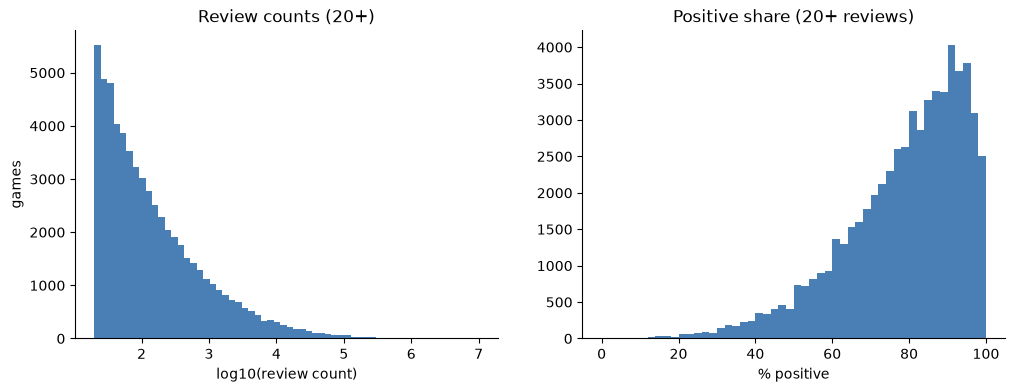

In [3]:
g = q("SELECT review_count, pct_positive FROM games WHERE review_count >= 20")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log10(g["review_count"]), bins=60, color="#4a7fb5")
ax[0].set(xlabel="log10(review count)", ylabel="games", title="Review counts (20+)")
ax[1].hist(g["pct_positive"], bins=50, color="#4a7fb5")
ax[1].set(xlabel="% positive", title="Positive share (20+ reviews)")
plt.show()

Spot check: relevant tags for a few well-known games, compared against their store pages.

In [4]:
q("""
SELECT g.name, string_agg(t.name || ' (' || round(gt.weight_share, 2) || ')', ', ' ORDER BY gt.rank) AS tags
FROM games g JOIN game_tags gt USING (appid) JOIN tags t USING (tagid)
WHERE g.appid IN (646570, 413150, 1145360, 892970, 105600) AND gt.relevant
GROUP BY g.name
""")

name,tags
str,str
"""Valheim""","""Open World Survival Craft (1.0), Survival (0.94), Online Co-Op (0.9), Open World (0.86), Multiplayer (0.85), Building (0.75), Crafting (0.69), Base Building (0.67), Exploration (0.63), Co-op (0.6)"""
"""Stardew Valley""","""Farming Sim (1.0), Pixel Graphics (0.92), Multiplayer (0.91), Life Sim (0.89), RPG (0.8), Relaxing (0.8), Simulation (0.64), Agriculture (0.64), Sandbox (0.55), Crafting (0.55)"""
"""Hades""","""Action Roguelike (1.0), Roguelite (0.73), Hack and Slash (0.71), Mythology (0.7), Indie (0.7), Action (0.6), Roguelike (0.59), Singleplayer (0.55), Great Soundtrack (0.53), Story Rich (0.52)"""
"""Terraria""","""Open World Survival Craft (1.0), Sandbox (0.98), Survival (0.79), Multiplayer (0.78), 2D (0.78), Pixel Graphics (0.71), Adventure (0.71), Crafting (0.65), Building (0.62), Exploration (0.55)"""
"""Slay the Spire""","""Roguelike Deckbuilder (1.0), Card Game (0.91), Card Battler (0.88), Roguelike (0.83), Deckbuilding (0.66), Turn-Based (0.6), Strategy (0.47), Singleplayer (0.41), Roguelite (0.39), Replay Value (0.33)"""


## 2. Tag relevance thresholds

Each game has up to 20 tags ranked by player votes. How fast does the vote share fall with rank? If tags past rank ~10 carry only a small share of the top tag's votes, they're mostly noise.

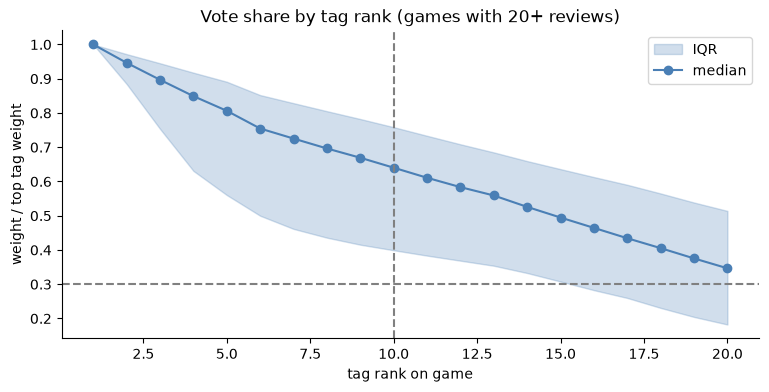

rank,p25,p50,p75
i64,f64,f64,f64
1,1.0,1.0,1.0
2,0.88452,0.946402,0.971831
3,0.753533,0.896875,0.945166
4,0.630907,0.849162,0.91773
5,0.560451,0.806364,0.891198
6,0.5,0.754608,0.852255
7,0.461593,0.725316,0.828685
8,0.435968,0.696407,0.80531
9,0.415482,0.669314,0.782419


In [5]:
r = q("""
SELECT gt.rank,
       quantile_cont(weight_share, 0.25) AS p25,
       median(weight_share) AS p50,
       quantile_cont(weight_share, 0.75) AS p75
FROM game_tags gt JOIN games g USING (appid)
WHERE g.review_count >= 20
GROUP BY gt.rank ORDER BY gt.rank
""")
plt.fill_between(r["rank"], r["p25"], r["p75"], alpha=0.25, color="#4a7fb5", label="IQR")
plt.plot(r["rank"], r["p50"], marker="o", color="#4a7fb5", label="median")
plt.axhline(0.3, ls="--", c="gray")
plt.axvline(10, ls="--", c="gray")
plt.xlabel("tag rank on game")
plt.ylabel("weight / top tag weight")
plt.legend()
plt.title("Vote share by tag rank (games with 20+ reviews)")
plt.show()
r

**Sensitivity check:** how the threshold choice changes tags per game and the number of analyzable pairs (≥15 games).

In [6]:
rows = []
for max_rank in (5, 8, 10, 12, 20):
    for min_share in (0.2, 0.3, 0.5, 1.01):
        res = con.execute(
            """
            WITH rel AS (
                SELECT gt.appid, gt.tagid FROM game_tags gt JOIN games g USING (appid)
                WHERE g.review_count >= 20 AND (gt.rank <= $r OR gt.weight_share >= $s)
            ), per_game AS (SELECT appid, COUNT(*) n FROM rel GROUP BY appid),
            pairs AS (
                SELECT a.tagid, b.tagid, COUNT(*) n FROM rel a JOIN rel b
                ON a.appid = b.appid AND a.tagid < b.tagid GROUP BY ALL HAVING COUNT(*) >= 15
            )
            SELECT (SELECT AVG(n) FROM per_game), (SELECT COUNT(*) FROM pairs)
        """,
            {"r": max_rank, "s": min_share},
        ).fetchone()
        rows.append(
            {
                "max_rank": max_rank,
                "min_share": str(min_share) if min_share <= 1 else "off",
                "tags_per_game": round(res[0], 1),
                "pairs_15plus": res[1],
            }
        )
sens = pl.DataFrame(rows)
sens.pivot(on="min_share", index="max_rank", values="pairs_15plus")

max_rank,0.2,0.3,0.5,off
i64,i64,i64,i64,i64
5,33625,31986,27552,5573
8,33671,32075,28080,12675
10,33730,32204,28663,17369
12,33814,32430,29384,21795
20,35204,35204,35204,35204


In [7]:
sens.pivot(on="min_share", index="max_rank", values="tags_per_game")

max_rank,0.2,0.3,0.5,off
i64,f64,f64,f64,f64
5,15.0,14.0,11.2,4.9
8,15.1,14.2,12.0,7.6
10,15.2,14.3,12.5,9.3
12,15.3,14.6,13.1,10.9
20,16.0,16.0,16.0,16.0


## 3. Combo support at the chosen thresholds

How many pairs and triples have at least 15 / 30 / 100 games? This sets how deep the "hidden gems" search can go.

In [8]:
con.execute("""
CREATE OR REPLACE TEMP TABLE rel AS
SELECT gt.appid, gt.tagid FROM game_tags gt JOIN games g USING (appid)
WHERE g.review_count >= 20 AND gt.relevant
""")
q("""
WITH pairs AS (
  SELECT a.tagid t1, b.tagid t2, COUNT(*) n FROM rel a JOIN rel b
  ON a.appid = b.appid AND a.tagid < b.tagid GROUP BY ALL
), triples AS (
  SELECT a.tagid t1, b.tagid t2, c.tagid t3, COUNT(*) n FROM rel a
  JOIN rel b ON a.appid = b.appid AND a.tagid < b.tagid
  JOIN rel c ON a.appid = c.appid AND b.tagid < c.tagid
  GROUP BY ALL HAVING COUNT(*) >= 15
)
SELECT 'pairs' AS kind, SUM((n>=15)::INT) n15, SUM((n>=30)::INT) n30, SUM((n>=100)::INT) n100 FROM pairs
UNION ALL
SELECT 'triples', SUM((n>=15)::INT), SUM((n>=30)::INT), SUM((n>=100)::INT) FROM triples
""")

kind,n15,n30,n100
str,"decimal[38,0]","decimal[38,0]","decimal[38,0]"
"""pairs""",17369,11351,4566
"""triples""",71813,34753,8089


## 4. Near-synonym tags

Pairs where most games with one tag also have the other (e.g. Roguelike/Roguelite). Their "combo" mostly restates one tag, so they need merging or excluding in the analysis.

In [9]:
q("""
WITH n AS (SELECT tagid, COUNT(*) n FROM rel GROUP BY tagid),
pairs AS (
  SELECT a.tagid t1, b.tagid t2, COUNT(*) n_both FROM rel a JOIN rel b
  ON a.appid = b.appid AND a.tagid < b.tagid GROUP BY ALL HAVING COUNT(*) >= 30
)
SELECT ta.name AS tag_a, tb.name AS tag_b, n_both,
       round(n_both / na.n, 2) AS p_b_given_a, round(n_both / nb.n, 2) AS p_a_given_b
FROM pairs p
JOIN n na ON na.tagid = p.t1 JOIN n nb ON nb.tagid = p.t2
JOIN tags ta ON ta.tagid = p.t1 JOIN tags tb ON tb.tagid = p.t2
WHERE least(n_both / na.n, n_both / nb.n) >= 0.5
ORDER BY least(n_both / na.n, n_both / nb.n) DESC
LIMIT 25
""")

tag_a,tag_b,n_both,p_b_given_a,p_a_given_b
str,str,i64,f64,f64
"""Nudity""","""Sexual Content""",4391,0.92,0.8
"""Gore""","""Violent""",1034,0.57,0.56
"""Roguelike""","""Roguelite""",1706,0.56,0.54
"""Naval Combat""","""Naval""",94,0.64,0.51
"""Deckbuilding""","""Card Battler""",525,0.5,0.57


## 5. First look: naive pair scores

No shrinkage or modeling yet, just mean % positive per pair compared with the average of its two tags' means. This only shows the *shape* of the data; M3 replaces it with the proper method (empirical-Bayes scores plus an additive baseline model).

In [10]:
q("""
WITH s AS (SELECT r.appid, r.tagid, g.pct_positive p FROM rel r JOIN games g USING (appid)),
single AS (SELECT tagid, AVG(p) m FROM s GROUP BY tagid),
pairs AS (
  SELECT a.tagid t1, b.tagid t2, COUNT(*) n, AVG(a.p) m FROM s a JOIN s b
  ON a.appid = b.appid AND a.tagid < b.tagid GROUP BY ALL HAVING COUNT(*) >= 30
)
SELECT ta.name || ' + ' || tb.name AS pair, n, round(p.m, 1) AS mean_pct,
       round(p.m - (s1.m + s2.m) / 2, 1) AS naive_lift
FROM pairs p JOIN single s1 ON s1.tagid = t1 JOIN single s2 ON s2.tagid = t2
JOIN tags ta ON ta.tagid = t1 JOIN tags tb ON tb.tagid = t2
ORDER BY naive_lift DESC LIMIT 20
""")

pair,n,mean_pct,naive_lift
str,i64,f64,f64
"""Tabletop + Incremental""",46,88.4,10.5
"""Dark + LGBTQ+""",45,91.4,9.7
"""Utilities + Idler""",63,89.1,9.7
"""Dark + Dating Sim""",34,88.9,9.6
"""Horror + Turn-Based Combat""",35,87.9,9.2
"""Historical + Text-Based""",42,89.5,9.0
"""Relaxing + Grid-Based Movement""",44,93.3,8.9
"""Anime + Crime""",32,87.8,8.9
"""RPG + Psychological""",46,87.4,8.8


## Takeaways (first pass, 2026-11-18)

- **Data looks right.** 59,853 games have 20+ reviews (median 93 reviews). Spot-checked tags for Hades, Slay the Spire, Stardew Valley, Terraria and Valheim all match their store pages.
- **Vote share is a weak noise filter.** Shares fall slowly: the median 20th tag still has about 35% of the top tag's votes. So the `share >= 0.3` clause brings back almost all 20 tags (14.3 relevant tags per game against 16.0 total). A rank-only cutoff (`top 10`, 9.3 per game) is the cleaner definition of "core descriptors" and still leaves about 17k pairs with 15+ games. **Decision: top 10 only** (`tag_max_rank=10`, `tag_min_share=None`). Sections 3–5 above are computed with this rule.
- **Support is plentiful.** See section 3 for pair and triple counts under the top-10 rule. Triples have to be filtered hard (CI, support ≥ 30) before export to the web.
- **Synonyms are few but real:** Nudity/Sexual Content/Hentai, Roguelike/Roguelite, Gore/Violent, Card Game/Card Battler/Deckbuilding, Co-op/Online Co-Op, Horror/Psychological Horror. Exclude same-family pairs from the "hidden gems" ranking.
- **Non-game tags leak in** (Utilities, Design & Illustration) on apps Steam lists as games. Consider excluding software-only tags in M3.
- **The naive lift top 20 is dominated by about 30-game combos** with lifts of +8–11 points. This is exactly the small-sample noise that shrinkage and CI-lower-bound ranking need to handle in M3.